# 02 · Preprocessing, reference labels, candidates and features
Walk-through on train trip `00000048`, using exactly the functions the pipeline uses (`src/pathsnap/core.py`).

In [1]:
import os, sys, json, time, warnings
ROOT = os.path.abspath("..")
sys.path.insert(0, os.path.join(ROOT, "src")); sys.path.insert(0, os.path.join(ROOT, "scripts"))
os.chdir(os.path.join(ROOT, "scripts"))  # scripts use paths relative to the repo
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, IFrame, HTML
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
DATA, RES, FIG = os.path.join(ROOT, "data"), os.path.join(ROOT, "results"), os.path.join(ROOT, "results", "figures")

In [2]:
from pathsnap.core import load_trip, align_route, build_candidates, arc_geometry, FEATURES, CAND_RADIUS_M, CAND_MAX_K
tr = load_trip(f"{DATA}/train/00000048")
print("GPS points:", len(tr.track), "| nodes:", len(tr.nodes), "| arcs:", len(tr.arcs), "| route arcs:", len(tr.route))
print("Projected GPS (local Azimuthal Equidistant, metres) – first rows:\n", tr.xy[:3].round(2))

GPS points: 1240 | nodes: 1308 | arcs: 2592 | route arcs: 149
Projected GPS (local Azimuthal Equidistant, metres) – first rows:
 [[-1.01457e+03  3.80000e-01]
 [-1.01995e+03 -5.96000e+00]
 [-1.02197e+03 -1.35300e+01]]


## 1. Why a local projection?
Degrees are not metres, and one degree of longitude shrinks with latitude. We compare the projected distance with the geodesic (haversine) distance for consecutive points.

In [3]:
lon, lat = np.radians(tr.track[:,0]), np.radians(tr.track[:,1])
hav = 2*6371008.8*np.arcsin(np.sqrt(np.sin(np.diff(lat)/2)**2 + np.cos(lat[:-1])*np.cos(lat[1:])*np.sin(np.diff(lon)/2)**2))
proj = np.hypot(*np.diff(tr.xy, axis=0).T); deg = np.hypot(*np.diff(tr.track[:,:2], axis=0).T)
print(f"max |projected - haversine| = {np.abs(proj-hav).max():.4f} m over {len(hav)} steps")
print(f"ratio of raw-degree distance to metres varies: {np.min(deg[hav>1]/hav[hav>1]):.2e} .. {np.max(deg[hav>1]/hav[hav>1]):.2e} (not a constant!)")

max |projected - haversine| = 0.0945 m over 1239 steps
ratio of raw-degree distance to metres varies: 8.99e-06 .. 1.49e-05 (not a constant!)


## 2. Per-observation reference labels (monotone DP alignment)
`.route` lists arcs, not one arc per point. Each GPS point is assigned to a route arc so that the route order is preserved and the total point-to-segment distance is minimised.

label distance (m): median 7.10, p90 16.17, max 34.70
route index is non-decreasing: True


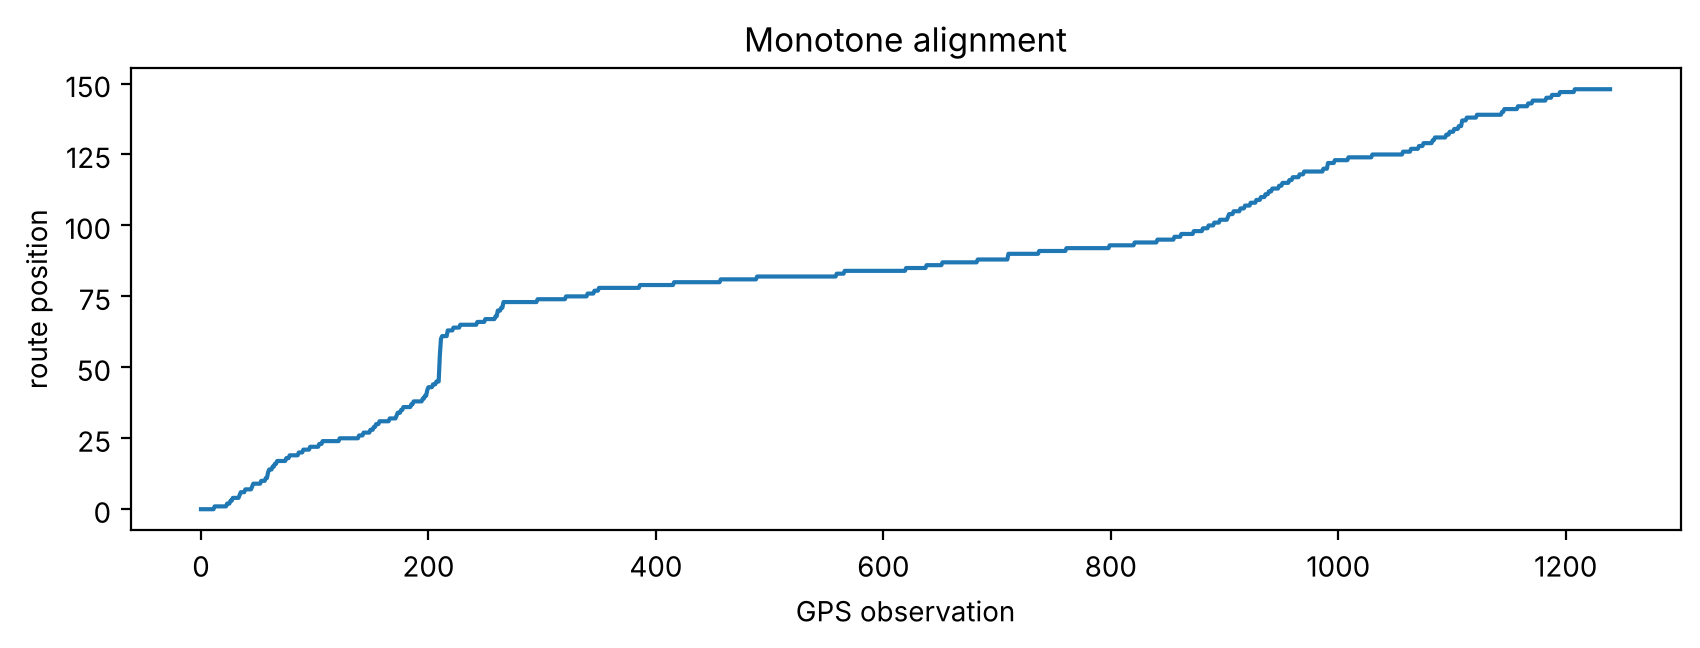

In [4]:
lab, ld, k = align_route(tr)
print("label distance (m): median %.2f, p90 %.2f, max %.2f" % (np.median(ld), np.percentile(ld, 90), ld.max()))
print("route index is non-decreasing:", bool(np.all(np.diff(k) >= 0)))
plt.figure(figsize=(10,3)); plt.plot(k); plt.xlabel("GPS observation"); plt.ylabel("route position"); plt.title("Monotone alignment"); plt.show()

## 3. Candidate generation and features
Candidates are arcs within 50 m (max 8 per point). If there are none, the 3 nearest within 300 m are used.

In [5]:
t0 = time.time(); cand = build_candidates(tr, lab); print(f"{len(cand)} candidate rows in {time.time()-t0:.2f}s")
print("candidates per point:", cand.groupby("obs").size().describe().round(2).to_dict())
print("reference arc present in candidates:", round(cand.groupby("obs").y.max().mean(), 4))
display(cand[["obs","arc"] + FEATURES + ["y"]].head(8).round(3))

7208 candidate rows in 0.16s
candidates per point: {'count': 1240.0, 'mean': 5.81, 'std': 2.23, 'min': 2.0, '25%': 4.0, '50%': 6.0, '75%': 8.0, 'max': 8.0}
reference arc present in candidates: 1.0


,obs,arc,dist,dist_rank,dist_minus_min,dist_ratio_min,n_cand,bearing_diff,cos_bearing,speed,arc_len,proj_t,ctx_dist_mean,ctx_dist_max,ctx_bearing_diff,is_twoway,out_deg_to,in_deg_from,gps_jump,y
0,0,571,8.815,1.0,0.000,1.000,8,24.087,0.913,7.876,95.927,0.053,10.806,15.243,12.591,1.0,2,2,0.0,1
1,0,570,8.815,2.0,0.000,1.000,8,155.913,-0.913,7.876,95.927,0.947,10.806,15.243,167.409,1.0,2,2,0.0,0
2,0,749,10.165,3.0,1.350,1.138,8,28.957,0.875,7.876,23.707,1.000,16.048,28.884,7.721,1.0,2,3,0.0,0
3,0,572,10.165,4.0,1.350,1.138,8,151.043,-0.875,7.876,23.707,0.000,16.048,28.884,172.279,1.0,3,2,0.0,0
4,0,750,29.479,5.0,20.665,3.106,8,90.714,-0.012,7.876,9.039,0.000,35.896,51.033,127.392,1.0,2,3,0.0,0
5,0,751,29.479,6.0,20.665,3.106,8,102.251,-0.212,7.876,54.589,0.000,35.894,51.021,65.573,1.0,3,3,0.0,0
6,0,840,29.479,7.0,20.665,3.106,8,89.286,0.012,7.876,9.039,1.000,35.896,51.033,52.608,1.0,3,2,0.0,0
7,0,752,29.479,8.0,20.665,3.106,8,77.749,0.212,7.876,54.589,1.000,35.894,51.021,114.427,1.0,3,3,0.0,0


## 4. Why heading features matter: nearest-arc baseline vs. features

Nearest-arc Top-1 on this trip: 0.496


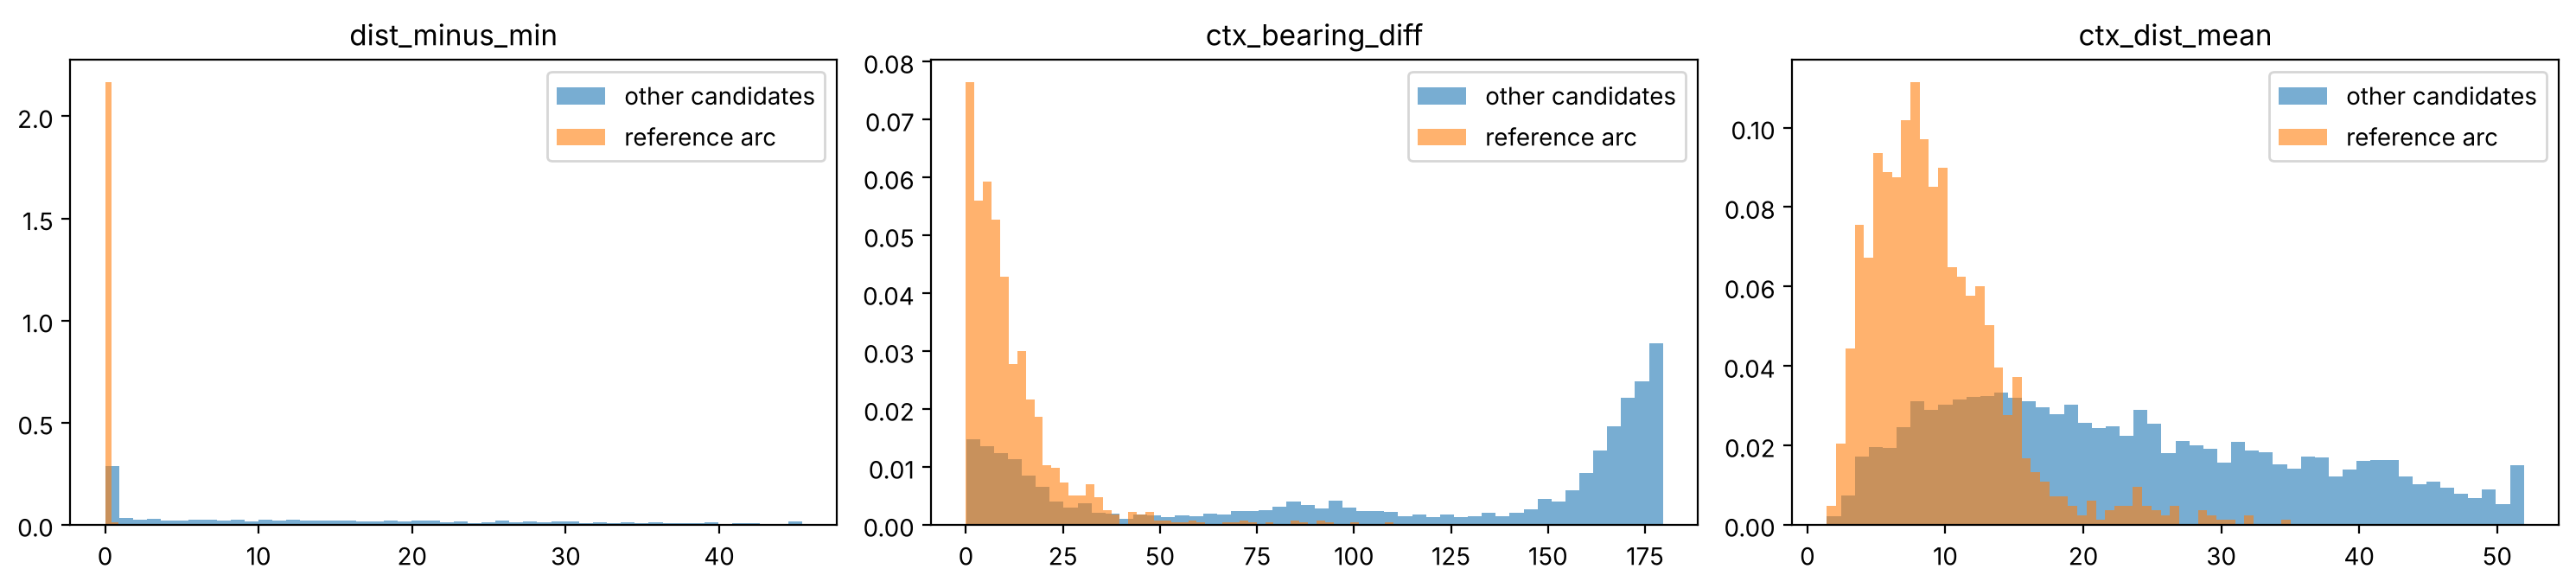

In [6]:
near = cand.loc[cand.groupby("obs").dist.idxmin()]
print("Nearest-arc Top-1 on this trip:", round(near.y.mean(), 4))
pos = cand[cand.y==1]; neg = cand[cand.y==0]
fig, ax = plt.subplots(1, 3, figsize=(15,3.5))
for a, f in zip(ax, ["dist_minus_min", "ctx_bearing_diff", "ctx_dist_mean"]):
    a.hist(np.clip(neg[f], 0, np.percentile(cand[f], 99)), bins=50, alpha=.6, density=True, label="other candidates")
    a.hist(np.clip(pos[f], 0, np.percentile(cand[f], 99)), bins=50, alpha=.6, density=True, label="reference arc"); a.set_title(f); a.legend()
plt.tight_layout(); plt.show()

## 5. Full dataset build (all trips)
Run `02_build_dataset.py` (optionally `--shard k --nshards 4` on each laptop, then `02b_merge_shards.py`). Here we load the merged tables.

In [7]:
c = pd.read_parquet(f"{RES}/data/obs_train.parquet"); s = pd.read_parquet(f"{RES}/data/obs_student_test.parquet")
print("train observations:", len(c), "| student_test observations:", len(s))
print("candidate miss rate – train: %.4f, student_test: %.4f" % (1-c.has_cand.mean(), 1-s.has_cand.mean()))

train observations: 208417 | student_test observations: 19160
candidate miss rate – train: 0.1122, student_test: 0.0041
